# Import e caricamento dati

In [2]:
import os, sys, pickle, ast
import pandas as pd

sys.path.insert(0, os.path.abspath('..'))
from Sorgente.Preprocessing.preprocesing import Preprocessore
from Sorgente.Indicizzazione.indice_invertito import IndiceInvertito
from Sorgente.Recupero.metadati import GestoreMetadati
from Sorgente.Recupero.bm25 import CalcolatoreRanking, pulisci_titolo
import os
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv()

client = OpenAI(api_key=os.getenv('OPENAI_API_KEY'))

print('Librerie caricate.')

Librerie caricate.


In [3]:
indice = IndiceInvertito()
indice.carica('../Dati/Elaborati/indice_fever.pkl')

with open('../Notebook/corpus_fever_arricchito.pkl', 'rb') as f:
    corpus_arricchito = pickle.load(f)

preprocessore = Preprocessore()
metadati      = GestoreMetadati(corpus_arricchito)
ranking       = CalcolatoreRanking(indice, preprocessore, metadati)

df_campione = pd.read_csv('../Notebook/campione_dev_bilanciato.csv')
df_campione['url_documenti'] = df_campione['url_documenti'].apply(
    lambda x: ast.literal_eval(str(x)) if pd.notna(x) else []
)
df_campione['sentence_ids'] = df_campione['sentence_ids'].apply(
    lambda x: ast.literal_eval(str(x)) if pd.notna(x) else []
)

print(f'Setup completato. Claim: {len(df_campione):,}')

Setup completato. Claim: 1,500


In [4]:
# Funzione helper per estrarre frase dal corpus
def estrai_frase(lines: str, sentence_id: int) -> str:
    if not lines:
        return ''
    for riga in lines.split('\n'):
        riga = riga.strip()
        if not riga:
            continue
        parti = riga.split('\t', 1)
        if len(parti) == 2:
            try:
                if int(parti[0]) == sentence_id:
                    return parti[1].strip()
            except ValueError:
                continue
    return ''

print('Helper definito.')

Helper definito.


# Costruzione del prompt

In [5]:
# Prompt di sistema — istruzioni permanenti per l'LLM
# Definisce il ruolo, il compito e il formato dell'output
PROMPT_SISTEMA = """You are a fact-checking assistant.
Your task is to determine whether a given EVIDENCE supports, refutes, or is
insufficient to verify a CLAIM.

You must respond with EXACTLY one of these three labels:
  SUPPORTS         - the evidence clearly supports the claim
  REFUTES          - the evidence clearly contradicts the claim
  NOT ENOUGH INFO  - the evidence is insufficient to verify the claim

Rules:
  - Respond with the label only. No explanation, no punctuation.
  - Base your judgment solely on the provided evidence.
  - Do not use external knowledge."""


def costruisci_prompt_utente(claim: str, evidenza: str) -> str:
    """
    Costruisce il messaggio utente per la classificazione NLI.

    Struttura il testo in tre sezioni chiare:
        EVIDENCE: il documento recuperato da BM25
        CLAIM:    la claim da verificare
        Risposta: forza l'LLM a continuare con la label

    La struttura con 'Response:' alla fine è una tecnica di
    prompt engineering che riduce la probabilità che l'LLM
    produca testo extra prima della label.

    Args:
        claim:    testo della claim da verificare
        evidenza: testo del documento recuperato

    Returns:
        Stringa del prompt utente
    """
    return f"""EVIDENCE: {evidenza}

CLAIM: {claim}

Response:"""


# Test visivo del prompt su un esempio reale
claim_prova    = 'Nikolaj Coster-Waldau worked with the Fox Broadcasting Company.'
evidenza_prova = 'He then played the leading man in the short-lived Fox series New Amsterdam.'

print('PROMPT DI SISTEMA:')
print('=' * 60)
print(PROMPT_SISTEMA)
print()
print('PROMPT UTENTE:')
print('=' * 60)
print(costruisci_prompt_utente(claim_prova, evidenza_prova))

PROMPT DI SISTEMA:
You are a fact-checking assistant.
Your task is to determine whether a given EVIDENCE supports, refutes, or is
insufficient to verify a CLAIM.

You must respond with EXACTLY one of these three labels:
  SUPPORTS         - the evidence clearly supports the claim
  REFUTES          - the evidence clearly contradicts the claim
  NOT ENOUGH INFO  - the evidence is insufficient to verify the claim

Rules:
  - Respond with the label only. No explanation, no punctuation.
  - Base your judgment solely on the provided evidence.
  - Do not use external knowledge.

PROMPT UTENTE:
EVIDENCE: He then played the leading man in the short-lived Fox series New Amsterdam.

CLAIM: Nikolaj Coster-Waldau worked with the Fox Broadcasting Company.

Response:


# Chiamata LLM con classificazione singola

In [6]:
# Label valide — esattamente le stesse del dataset FEVER
LABEL_VALIDE = {'SUPPORTS', 'REFUTES', 'NOT ENOUGH INFO'}


def classifica_coppia(claim: str, evidenza: str) -> str:
    """
    Classifica la relazione tra una claim e un'evidenza.

    Invia il prompt all'LLM e analizza la risposta.
    Temperatura=0 per output deterministico e riproducibile.
    Max_tokens=10 perché la risposta deve essere una sola label.

    Se l'LLM restituisce testo non atteso, restituisce
    'NOT ENOUGH INFO' come fallback sicuro (meglio non pronunciarsi
    che dare una label errata con sicurezza).

    Args:
        claim:    testo della claim
        evidenza: testo del documento (premessa)

    Returns:
        Una delle tre label: 'SUPPORTS', 'REFUTES', 'NOT ENOUGH INFO'
    """
    if not evidenza or not evidenza.strip():
        return 'NOT ENOUGH INFO'

    try:
        risposta = client.chat.completions.create(
            model      = 'gpt-4o-mini',
            messages   = [
                {'role': 'system', 'content': PROMPT_SISTEMA},
                {'role': 'user',   'content': costruisci_prompt_utente(claim, evidenza)}
            ],
            temperature = 0.0,   # deterministico — stessa risposta per stesso input
            max_tokens  = 10     # la label è al massimo 3 parole
        )
        testo_risposta = risposta.choices[0].message.content.strip().upper()

        # Verifica che la risposta sia una label valida
        if testo_risposta in LABEL_VALIDE:
            return testo_risposta

        # Gestione parziale: l'LLM potrebbe restituire 'SUPPORTS.' con punto
        testo_pulito = testo_risposta.rstrip('.')
        if testo_pulito in LABEL_VALIDE:
            return testo_pulito

        # Fallback: label non riconoscibile
        print(f'  ⚠️  Risposta LLM non riconosciuta: "{testo_risposta}" → fallback NOT ENOUGH INFO')
        return 'NOT ENOUGH INFO'

    except Exception as e:
        print(f'  ❌ Errore API: {e}')
        return 'NOT ENOUGH INFO'


print('Funzione classificazione definita.')

Funzione classificazione definita.


In [7]:
# Test su 3 coppie manuali con label attesa nota
coppie_test = [
    {
        'claim':    'Nikolaj Coster-Waldau worked with the Fox Broadcasting Company.',
        'evidenza': 'He then played the leading man in the short-lived Fox series New Amsterdam.',
        'attesa':   'SUPPORTS'
    },
    {
        'claim':    'The Eiffel Tower is located in Berlin.',
        'evidenza': 'The Eiffel Tower is a wrought-iron lattice tower on the Champ de Mars in Paris, France.',
        'attesa':   'REFUTES'
    },
    {
        'claim':    'Obama was born in 1985.',
        'evidenza': 'Barack Obama served as the 44th president of the United States.',
        'attesa':   'NOT ENOUGH INFO'
    }
]

print('TEST CLASSIFICAZIONE — 3 coppie manuali')
print('=' * 60)
for coppia in coppie_test:
    label = classifica_coppia(coppia['claim'], coppia['evidenza'])
    esito = '✅' if label == coppia['attesa'] else '❌'
    print(f"\n{esito} Claim:    {coppia['claim']}")
    print(f"   Evidenza: {coppia['evidenza'][:80]}")
    print(f"   Attesa:   {coppia['attesa']:<20} Ottenuta: {label}")

TEST CLASSIFICAZIONE — 3 coppie manuali

✅ Claim:    Nikolaj Coster-Waldau worked with the Fox Broadcasting Company.
   Evidenza: He then played the leading man in the short-lived Fox series New Amsterdam.
   Attesa:   SUPPORTS             Ottenuta: SUPPORTS

✅ Claim:    The Eiffel Tower is located in Berlin.
   Evidenza: The Eiffel Tower is a wrought-iron lattice tower on the Champ de Mars in Paris, 
   Attesa:   REFUTES              Ottenuta: REFUTES

❌ Claim:    Obama was born in 1985.
   Evidenza: Barack Obama served as the 44th president of the United States.
   Attesa:   NOT ENOUGH INFO      Ottenuta: REFUTES


# Aggregazione dei verdetti

In [9]:
def aggrega_verdetti(
    verdetti:  list[str],
    punteggi:  list[float]
) -> tuple[str, dict]:
    """
    Aggrega i verdetti di K documenti in un verdetto finale.

    Usa la maggioranza pesata: somma i punteggi BM25 per ogni
    label e sceglie quella con il punteggio aggregato maggiore.

    Perché pesare per BM25:
        Un documento con punteggio BM25 alto è più rilevante
        per la claim. Il suo verdetto deve pesare di più
        rispetto a un documento recuperato con bassa rilevanza.

    Args:
        verdetti: lista di label ('SUPPORTS', 'REFUTES', 'NOT ENOUGH INFO')
        punteggi: lista di punteggi BM25 corrispondenti

    Returns:
        Tupla (verdetto_finale, pesi_per_label):
            verdetto_finale: label con peso aggregato massimo
            pesi_per_label:  {'SUPPORTS': x, 'REFUTES': y, 'NOT ENOUGH INFO': z}
    """
    if not verdetti:
        return 'NOT ENOUGH INFO', {}

    pesi = {'SUPPORTS': 0.0, 'REFUTES': 0.0, 'NOT ENOUGH INFO': 0.0}

    for verdetto, punteggio in zip(verdetti, punteggi):
        if verdetto in pesi:
            pesi[verdetto] += punteggio

    verdetto_finale = max(pesi, key=lambda k: pesi[k])
    return verdetto_finale, pesi


# Test aggregazione su scenari diversi
print('TEST AGGREGAZIONE VERDETTI')
print('=' * 55)

scenari = [
    {
        'desc':      '3 SUPPORTS pesanti, 1 REFUTES leggero',
        'verdetti':  ['SUPPORTS', 'SUPPORTS', 'SUPPORTS', 'REFUTES'],
        'punteggi':  [20.0, 18.0, 15.0, 5.0],
        'atteso':    'SUPPORTS'
    },
    {
        'desc':      '1 REFUTES pesante, 3 SUPPORTS leggeri',
        'verdetti':  ['REFUTES', 'SUPPORTS', 'SUPPORTS', 'SUPPORTS'],
        'punteggi':  [25.0, 3.0, 2.0, 1.0],
        'atteso':    'REFUTES'
    },
    {
        'desc':      'Tutti NOT ENOUGH INFO',
        'verdetti':  ['NOT ENOUGH INFO', 'NOT ENOUGH INFO', 'NOT ENOUGH INFO'],
        'punteggi':  [10.0, 8.0, 6.0],
        'atteso':    'NOT ENOUGH INFO'
    }
]

for scenario in scenari:
    finale, pesi = aggrega_verdetti(scenario['verdetti'], scenario['punteggi'])
    esito = '✅' if finale == scenario['atteso'] else '❌'
    print(f"\n{esito} {scenario['desc']}")
    print(f"   Pesi: {pesi}")
    print(f"   Verdetto finale: {finale}")

TEST AGGREGAZIONE VERDETTI

✅ 3 SUPPORTS pesanti, 1 REFUTES leggero
   Pesi: {'SUPPORTS': 53.0, 'REFUTES': 5.0, 'NOT ENOUGH INFO': 0.0}
   Verdetto finale: SUPPORTS

✅ 1 REFUTES pesante, 3 SUPPORTS leggeri
   Pesi: {'SUPPORTS': 6.0, 'REFUTES': 25.0, 'NOT ENOUGH INFO': 0.0}
   Verdetto finale: REFUTES

✅ Tutti NOT ENOUGH INFO
   Pesi: {'SUPPORTS': 0.0, 'REFUTES': 0.0, 'NOT ENOUGH INFO': 24.0}
   Verdetto finale: NOT ENOUGH INFO


# Pipeline NLI completaq

In [10]:
def verifica_claim(
    claim:            str,
    corpus_arricchito: dict,
    ranking:          CalcolatoreRanking,
    k:                int = 5
) -> dict:
    """
    Verifica una claim attraverso la pipeline completa IR + NLI.

    Passi:
        1. Recupera top-K documenti con BM25 esteso
        2. Estrae il testo di ogni documento dal corpus
        3. Classifica ogni coppia (claim, documento) con l'LLM
        4. Aggrega i verdetti con maggioranza pesata
        5. Restituisce il verdetto finale con tutti i dettagli

    Args:
        claim:             testo della claim da verificare
        corpus_arricchito: corpus con testo dei documenti
        ranking:           calcolatore BM25
        k:                 numero documenti da recuperare

    Returns:
        Dizionario con:
            'claim':          testo originale
            'verdetto':       label finale aggregata
            'pesi_label':     pesi aggregati per label
            'dettagli':       lista verdetti per documento
    """
    # Passo 1 — Recupero documenti
    risultati_bm25 = ranking.recupera_top_k(claim, k=k)
    if not risultati_bm25:
        return {
            'claim':      claim,
            'verdetto':   'NOT ENOUGH INFO',
            'pesi_label': {},
            'dettagli':   []
        }

    # Passi 2-3 — Estrai testo e classifica
    verdetti  = []
    punteggi  = []
    dettagli  = []

    for risultato in risultati_bm25:
        id_doc = risultato['id_doc']

        # Usa il testo completo del documento come evidenza
        # Troncato a 1000 caratteri per contenere i costi API
        doc = corpus_arricchito.get(id_doc, {})
        testo_evidenza = (doc.get('text', '') or '')[:1000]

        # Classificazione LLM
        label = classifica_coppia(claim, testo_evidenza)

        verdetti.append(label)
        punteggi.append(risultato['punteggio_finale'])
        dettagli.append({
            'id_doc':    id_doc,
            'titolo':    risultato['titolo'],
            'punteggio': risultato['punteggio_finale'],
            'verdetto':  label,
            'evidenza':  testo_evidenza[:200]
        })

    # Passo 4 — Aggregazione
    verdetto_finale, pesi = aggrega_verdetti(verdetti, punteggi)

    return {
        'claim':      claim,
        'verdetto':   verdetto_finale,
        'pesi_label': pesi,
        'dettagli':   dettagli
    }


print('Pipeline NLI completa definita.')

Pipeline NLI completa definita.


In [11]:
# Test pipeline completa su 5 claim reali del dataset FEVER
# Usiamo claim con label nota per verificare la correttezza

print('TEST PIPELINE COMPLETA — 5 CLAIM REALI')
print('=' * 65)

claim_per_label = {}
for label in ['SUPPORTS', 'REFUTES', 'NOT ENOUGH INFO']:
    esempi = df_campione[df_campione['label'] == label].head(2)
    claim_per_label[label] = esempi

corretti = 0
totale   = 0

for label_attesa, esempi in claim_per_label.items():
    for _, riga in esempi.iterrows():
        risultato = verifica_claim(
            riga['testo_claim'],
            corpus_arricchito,
            ranking,
            k=3
        )

        esito = '✅' if risultato['verdetto'] == label_attesa else '❌'
        if risultato['verdetto'] == label_attesa:
            corretti += 1
        totale += 1

        print(f"\n{esito} [{label_attesa}] {riga['testo_claim']}")
        print(f"   Verdetto:   {risultato['verdetto']}")
        print(f"   Pesi:       {risultato['pesi_label']}")
        print(f"   Documenti usati:")
        for d in risultato['dettagli']:
            print(f"     - {d['titolo']:<40} [{d['verdetto']}]")

print(f"\nAccuracy su {totale} claim: {corretti}/{totale} = {corretti/totale*100:.0f}%")

TEST PIPELINE COMPLETA — 5 CLAIM REALI

✅ [SUPPORTS] Alberto Contador was stripped of his wins.
   Verdetto:   SUPPORTS
   Pesi:       {'SUPPORTS': 27.9226, 'REFUTES': 0.0, 'NOT ENOUGH INFO': 22.752200000000002}
   Documenti usati:
     - Alberto Contador                         [SUPPORTS]
     - List of Formula One World Drivers' Champions [NOT ENOUGH INFO]
     - Stripped (Christina Aguilera album)      [NOT ENOUGH INFO]

✅ [SUPPORTS] In golf, players hit balls into holes.
   Verdetto:   SUPPORTS
   Pesi:       {'SUPPORTS': 62.367999999999995, 'REFUTES': 0.0, 'NOT ENOUGH INFO': 19.6022}
   Documenti usati:
     - Golf                                     [SUPPORTS]
     - U.S. Open (golf)                         [SUPPORTS]
     - Bowled                                   [NOT ENOUGH INFO]

✅ [REFUTES] US Airways Flight 1549 landed in Boise.
   Verdetto:   REFUTES
   Pesi:       {'SUPPORTS': 0.0, 'REFUTES': 84.849, 'NOT ENOUGH INFO': 0.0}
   Documenti usati:
     - Chesley Sullenberger 

# Valutazione su campione

In [12]:
from sklearn.metrics import classification_report, cohen_kappa_score

# Valuta su 30 claim bilanciate (10 per classe)
# Numero piccolo per contenere i costi API durante il test
CLAIM_PER_CLASSE = 10

label_vere      = []
label_predette  = []

print(f'Valutazione su {CLAIM_PER_CLASSE * 3} claim ({CLAIM_PER_CLASSE} per classe)...')
print('Ogni claim usa k=3 documenti → 3 chiamate API per claim')
print()

for label in ['SUPPORTS', 'REFUTES', 'NOT ENOUGH INFO']:
    campione = df_campione[df_campione['label'] == label].head(CLAIM_PER_CLASSE)
    print(f'Classificazione {label} ({len(campione)} claim)...')

    for _, riga in campione.iterrows():
        risultato = verifica_claim(
            riga['testo_claim'],
            corpus_arricchito,
            ranking,
            k=3
        )
        label_vere.append(label)
        label_predette.append(risultato['verdetto'])

print()
print('RISULTATI VALUTAZIONE NLI')
print('=' * 55)
print(classification_report(
    label_vere,
    label_predette,
    labels=['SUPPORTS', 'REFUTES', 'NOT ENOUGH INFO'],
    zero_division=0
))

kappa = cohen_kappa_score(label_vere, label_predette)
print(f'Kappa di Cohen: {kappa:.4f}')
print()
if kappa > 0.6:
    print('  → Accordo sostanziale (kappa > 0.6)')
elif kappa > 0.4:
    print('  → Accordo moderato (kappa > 0.4)')
else:
    print('  → Accordo debole (kappa ≤ 0.4)')

Valutazione su 30 claim (10 per classe)...
Ogni claim usa k=3 documenti → 3 chiamate API per claim

Classificazione SUPPORTS (10 claim)...
Classificazione REFUTES (10 claim)...
Classificazione NOT ENOUGH INFO (10 claim)...

RISULTATI VALUTAZIONE NLI
                 precision    recall  f1-score   support

       SUPPORTS       0.88      0.70      0.78        10
        REFUTES       0.73      0.80      0.76        10
NOT ENOUGH INFO       0.64      0.70      0.67        10

       accuracy                           0.73        30
      macro avg       0.75      0.73      0.74        30
   weighted avg       0.75      0.73      0.74        30

Kappa di Cohen: 0.6000

  → Accordo moderato (kappa > 0.4)


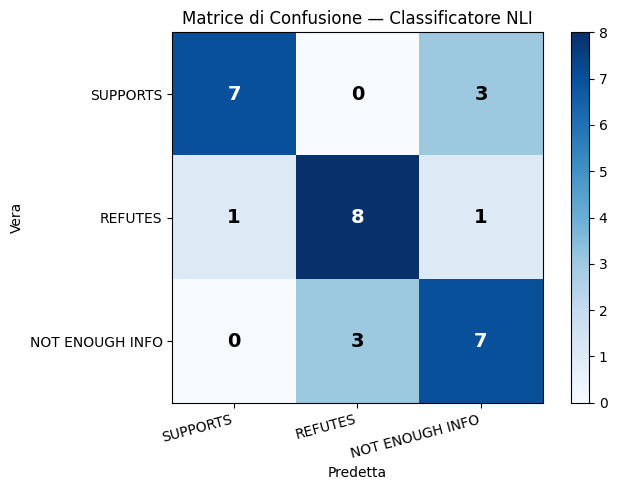

Salvata: matrice_confusione_nli.png


In [13]:
# Matrice di confusione — dove sbaglia il sistema?
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

classi = ['SUPPORTS', 'REFUTES', 'NOT ENOUGH INFO']
cm     = confusion_matrix(label_vere, label_predette, labels=classi)

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(len(classi)))
ax.set_yticks(range(len(classi)))
ax.set_xticklabels(classi, rotation=15, ha='right')
ax.set_yticklabels(classi)
ax.set_xlabel('Predetta')
ax.set_ylabel('Vera')
ax.set_title('Matrice di Confusione — Classificatore NLI')

for i in range(len(classi)):
    for j in range(len(classi)):
        colore = 'white' if cm[i, j] > cm.max() / 2 else 'black'
        ax.text(j, i, str(cm[i, j]), ha='center', va='center',
                color=colore, fontsize=14, fontweight='bold')

plt.colorbar(im)
plt.tight_layout()
plt.savefig('matrice_confusione_nli.png', dpi=150, bbox_inches='tight')
plt.show()
print('Salvata: matrice_confusione_nli.png')